In [1]:
%matplotlib ipympl

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import cm
import make_HPO_dms as mdms

In [35]:
HPO_DMS_x_file, HPO_DMS_z_file = 'HPO_dms_f12_x.txt', 'HPO_dms_f12_z.txt'
#HPO_DMS_x_file, HPO_DMS_z_file = 'HPO_dms_4th_order_x.txt', 'HPO_dms_4th_order_z.txt'
print(mdms.get_non_linear_p(HPO_DMS_x_file))
print(mdms.get_non_linear_p(HPO_DMS_z_file))


[  1.48332858   1.45449985 104.37954153   0.           0.
   0.        ]
[  1.48332858   1.45449985 104.37954153   0.           0.
   0.        ]


In [36]:
p_x, orders_x = mdms.get_coeffs_orders(HPO_DMS_x_file)
nonlin_p_x = mdms.get_non_linear_p(HPO_DMS_x_file)
dms_x = mdms.get_dms(p_x, nonlin_p_x.copy(), orders_x)

p_z, orders_z = mdms.get_coeffs_orders(HPO_DMS_z_file)
nonlin_p_z = mdms.get_non_linear_p(HPO_DMS_z_file)
dms_z = mdms.get_dms(p_z, nonlin_p_z.copy(), orders_z)

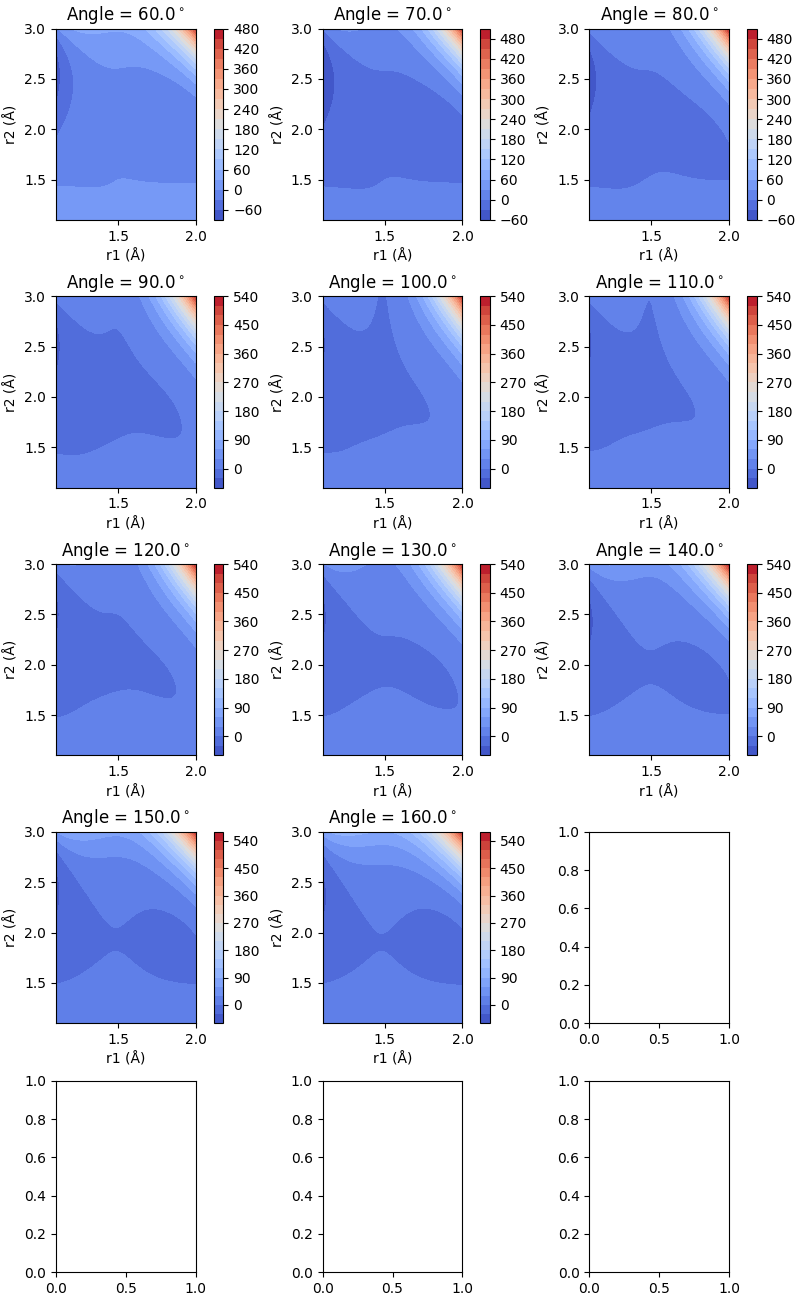

In [5]:
equilibriums = np.array([0.148350247959E+01,
                         0.145448124026E+01,
                         0.104386978891E+03])

r1_grid = np.linspace(1.1,2.0, 50)
r2_grid = np.linspace(1.1,3.0, 50)
a_grid = np.arange(60.0, 165.0, 10)

fig, ax = plt.subplots(5, 3, figsize=(8, 13),
                       constrained_layout=True)
ax = ax.flatten()

for i in range(len(a_grid)):
    angle = a_grid[i]
    r1r2_mesh = np.meshgrid(r1_grid, r2_grid)
    r1_mesh = r1r2_mesh[0]
    r2_mesh = r1r2_mesh[1]

    geometry_r1r2= np.zeros((len(r1_grid)*len(r2_grid), 
                           3) )
    geometry_r1r2[:, 0] = r1_mesh.flatten()
    geometry_r1r2[:, 1] = r2_mesh.flatten()
    geometry_r1r2[:, 2] = angle

    dms_x_vals = dms_x(geometry_r1r2)
    dms_x_vals = np.reshape(dms_x_vals, 
                        (len(r1_grid), len(r2_grid)) #shape 
                       )
    

    ax[i].set_title(f'Angle = {angle:.1f}$^\\circ$')
    ax[i].set_xlabel('r1 (Å)')
    ax[i].set_ylabel('r2 (Å)')

    contour = ax[i].contourf(
    r1_mesh, r2_mesh, dms_x_vals,
    levels=20,
    cmap=cm.coolwarm,
    )
    plt.colorbar(contour, ax=ax[i])

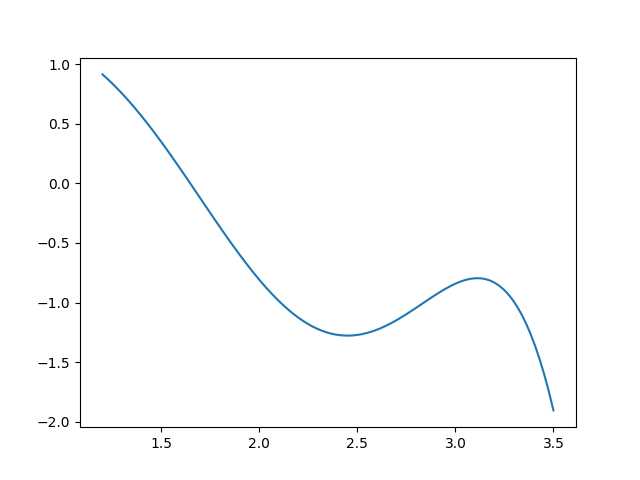

In [38]:
geometry1d = np.zeros((100, 3))
equilibriums = np.array([1.4833,
                         0.145448124026E+01,
                         104.3977])

#equilibriums = np.array([1.80,
#                         0.145448124026E+01,
#                         104.3977])

for j in range(3):
    geometry1d[:, j] = equilibriums[j]
    
geometry1d[:, 1] = np.linspace(1.2,3.5, 100)

plt.figure()

plt.plot(geometry1d[:, 1], dms_x(geometry1d), label='x-component')
#plt.plot(geometry1d[:, 1], dms_z(geometry1d), label='z-component')